# Chunk evaluation

Evaluate `chunk_document` output across every PDF in the fund registry (`config/funds.yaml`)
using `ChunkerEvaluator`: length distribution, coverage, fund breakdown, leftover artifacts
and near-duplicate chunks across funds.

In [1]:
import sys
from pathlib import Path

SRC_DIR = Path.cwd().parent
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import polars as pl

from rag.evaluation.chunking import ChunkerEvaluator
from rag.ingest.chunk import chunk_document
from rag.ingest.funds import document_info, fund_detector, load_registry
from rag.ingest.parse import parse_pdf

DATA_DIR = Path.cwd().parent / "data"
registry = load_registry()
list(registry.documents)

['FU_BF065_EN.pdf',
 'KID_BE6316179249_BG.pdf',
 '17126.pdf',
 '18325.pdf',
 '18368.pdf',
 '11074.pdf']

## Parse and chunk every document

Build one `ParsedDocument` and its chunks per file in the registry.

In [2]:
def chunk_pdf(file_name: str, doc):
    info = document_info(registry, file_name)
    detect_fund = fund_detector(registry, file_name)
    return chunk_document(doc, info, detect_fund=detect_fund)


documents = [parse_pdf(DATA_DIR / file_name) for file_name in registry.documents]
chunks = [
    chunk
    for file_name, doc in zip(registry.documents, documents)
    for chunk in chunk_pdf(file_name, doc)
]
print(f"{len(documents)} documents, {len(chunks)} chunks")

6 documents, 1573 chunks


In [3]:
evaluator = ChunkerEvaluator(chunks, documents)

## Length distribution

Chunks per document, with oversized (`> max_chars`) and tiny chunk counts.

In [4]:
evaluator.length_stats()

doc_id,chunks,min,median,p95,max,over_max,body_over_max,tiny
str,u32,i64,f64,f64,i64,u32,u32,u32
"""11074""",9,76,500.0,849.0,849,0,0,1
"""17126""",46,177,1220.5,1471.0,1495,0,0,1
"""18325""",54,159,1098.0,1464.0,1481,0,0,1
"""18368""",2,663,759.5,856.0,856,0,0,0
"""FU_BF065_EN""",1441,215,1286.0,1487.0,1566,2,1,0
"""KID_BE6316179249_BG""",21,165,948.0,1462.0,1472,0,0,1


## Coverage

Share of chunks with a detected fund / section, and how many parsed pages each document's chunks cover.

In [5]:
evaluator.coverage()

doc_id,chunks,share_with_fund,share_with_section,pages_covered,pages_parsed
str,u32,f64,f64,u32,i64
"""11074""",9,0.0,0.888889,1,1
"""17126""",46,1.0,1.0,9,9
"""18325""",54,1.0,1.0,10,10
"""18368""",2,1.0,0.5,1,1
"""FU_BF065_EN""",1441,0.955586,0.997224,556,556
"""KID_BE6316179249_BG""",21,1.0,1.0,4,4


## Fund breakdown

Chunks and page range per (umbrella fund, fund).

In [6]:
evaluator.fund_breakdown()

umbrella_fund,fund,chunks,documents,first_page,last_page
str,str,u32,list[str],i64,i64
"""Optimum Fund""",null,64,"[""FU_BF065_EN""]",1,24
"""Optimum Fund""","""Enhanced Intelligence Global A…",154,"[""17126"", ""FU_BF065_EN"", ""KID_BE6316179249_BG""]",1,514
"""Optimum Fund""","""K&H egészség""",30,"[""FU_BF065_EN""]",38,50
"""Optimum Fund""","""K&H egészség 2""",30,"[""FU_BF065_EN""]",50,62
"""Optimum Fund""","""K&H fix egészség 1""",30,"[""FU_BF065_EN""]",62,74
…,…,…,…,…,…
"""Optimum Fund""","""ČSOB Velmi opatrný""",28,"[""FU_BF065_EN""]",475,488
"""Optimum Fund""","""ČSOB Zdravotnictví a farmacie …",30,"[""FU_BF065_EN""]",488,499
"""ОББ ЕкспертИйз""","""ОББ ЕкспертИйз Дефанзивен Бала…",2,"[""18368""]",1,1


## Leftover artifacts

Markdown/markup residue, running headers, bare page numbers and mixed-script words that
survived cleaning, per document.

In [7]:
evaluator.artifacts()

doc_id,bold,underline,br,picture_marker,running_header,page_number_line,mixed_script_word
str,i64,i64,i64,i64,i64,i64,i64
"""11074""",0,0,0,0,0,0,0
"""17126""",0,0,0,0,0,0,0
"""18325""",0,0,0,0,0,0,0
"""18368""",0,0,0,0,0,0,0
"""FU_BF065_EN""",8,0,0,0,57,0,0
"""KID_BE6316179249_BG""",0,0,0,0,0,0,0


In [8]:
# Inspect a sample of chunks containing a given artifact
evaluator.artifact_examples("mixed_script_word")

doc_id,page_start,section,text
str,i64,str,str


## Near-duplicates across funds

Chunks that are near-identical (cosine similarity ≥ threshold) but belong to different funds — a sign the same boilerplate wasn't attributed consistently.

In [9]:
with pl.Config(tbl_rows=100, tbl_cols=150):
    print(evaluator.near_duplicates())

shape: (10_129, 9)
┌───────────┬───────────┬───────────┬───────────┬────────┬──────────┬────────┬──────────┬──────────┐
│ similarit ┆ fund_a    ┆ fund_b    ┆ doc_a     ┆ page_a ┆ doc_b    ┆ page_b ┆ section_ ┆ text_a   │
│ y         ┆ ---       ┆ ---       ┆ ---       ┆ ---    ┆ ---      ┆ ---    ┆ a        ┆ ---      │
│ ---       ┆ str       ┆ str       ┆ str       ┆ i64    ┆ str      ┆ i64    ┆ ---      ┆ str      │
│ f64       ┆           ┆           ┆           ┆        ┆          ┆        ┆ str      ┆          │
╞═══════════╪═══════════╪═══════════╪═══════════╪════════╪══════════╪════════╪══════════╪══════════╡
│ 1.0       ┆ World     ┆ ČSOB Glob ┆ FU_BF065_ ┆ 196    ┆ FU_BF065 ┆ 299    ┆ Informat ┆ |(i)|Nam │
│           ┆ Selection ┆ álních    ┆ EN        ┆        ┆ _EN      ┆        ┆ ion conc ┆ e|Bloomb │
│           ┆ 100-1     ┆ firem 8   ┆           ┆        ┆          ┆        ┆ erning   ┆ erg Code │
│           ┆           ┆           ┆           ┆        ┆          ┆   

In [10]:
evaluator.near_duplicate_rate()

0.7622377622377622

## Visualizations

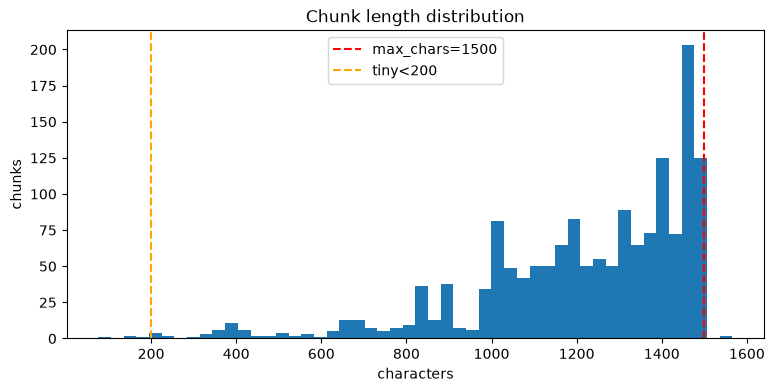

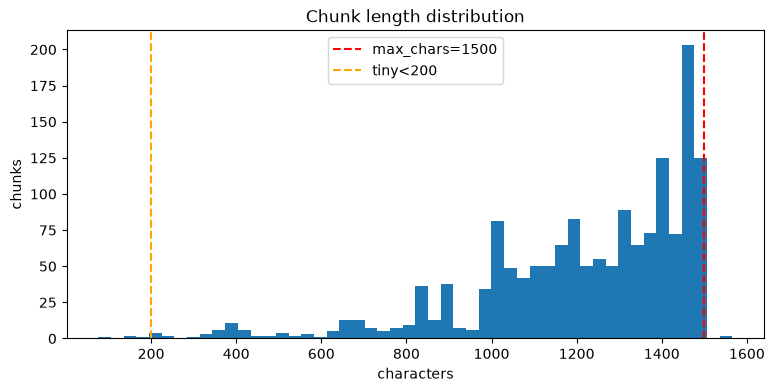

In [11]:
evaluator.plot_lengths()

/home/mtsatsev/rag/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/mtsatsev/rag/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


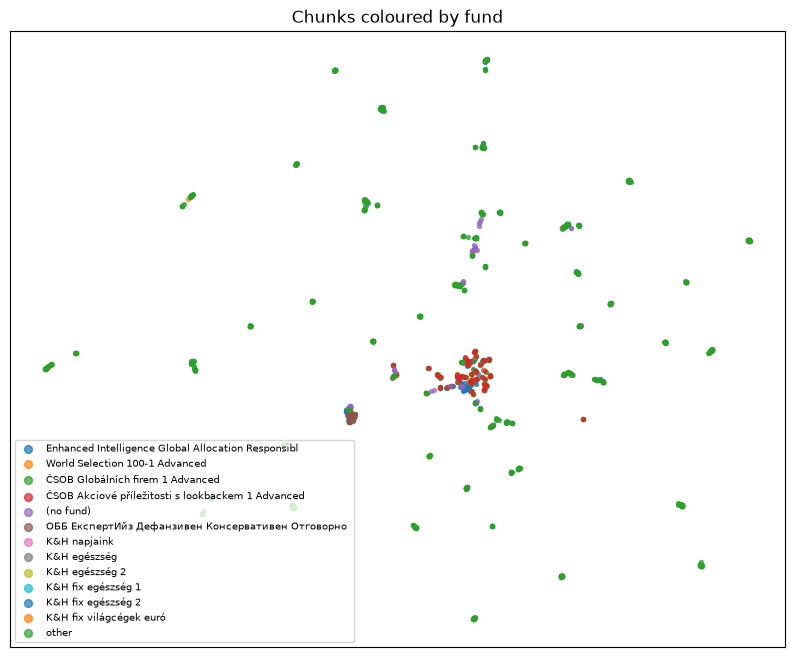

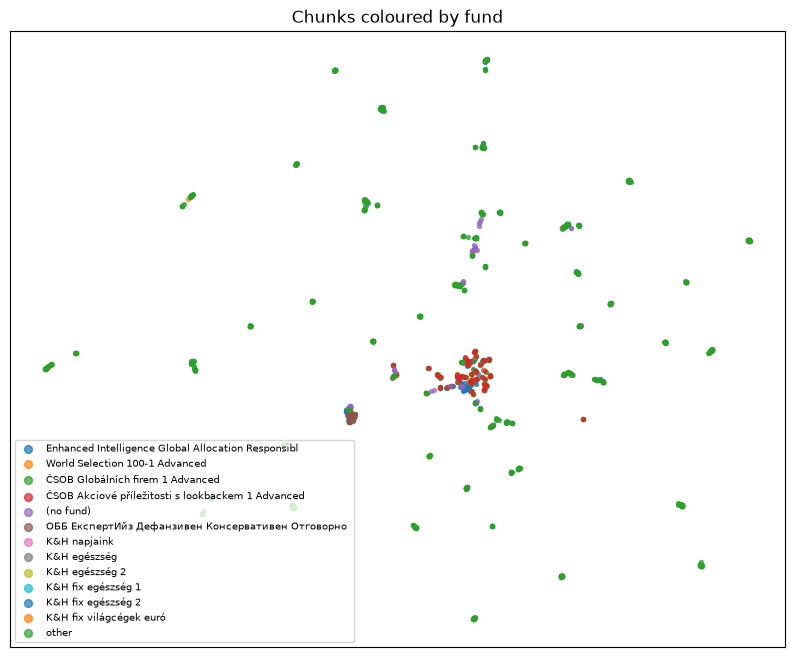

In [12]:
evaluator.plot_map(color_by="fund")